In [ ]:

# QuickBite Lab 05 - Model Analysis

import json
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.model_selection import StratifiedKFold, cross_val_predict

from latedeliveries.evaluation import calculate_cost
from latedeliveries.pipeline import load_and_split

# Project root (notebook is inside notebooks/)
PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

# Load saved results
cv_results = pd.read_csv(PROJECT_ROOT / "reports" / "cv_results.csv")

with open(PROJECT_ROOT / "reports" / "metrics.json") as file:
    metrics = json.load(file)

model = joblib.load(PROJECT_ROOT / "models" / "late_orders.joblib")

# Load data
X_train, X_test, y_train, y_test = load_and_split()

print("QuickBite Analysis")
print("Training orders:", len(X_train))
print("Testing orders:", len(X_test))
print("Late-order rate:", round(y_train.mean() * 100, 2), "%")


QuickBite Analysis
Training orders: 2250
Testing orders: 750
Late-order rate: 15.6 %


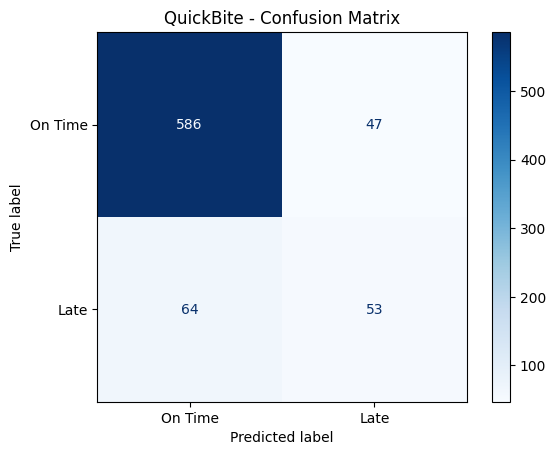

In [ ]:

# Plot the final test-set confusion matrix


# Convert the JSON list into a NumPy array
cm = np.array(metrics["confusion_matrix"])

# Create the confusion matrix display
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["On Time", "Late"],
)

# Plot the confusion matrix
display.plot(cmap="Blues", values_format="d")

plt.title("QuickBite - Confusion Matrix")
plt.show()


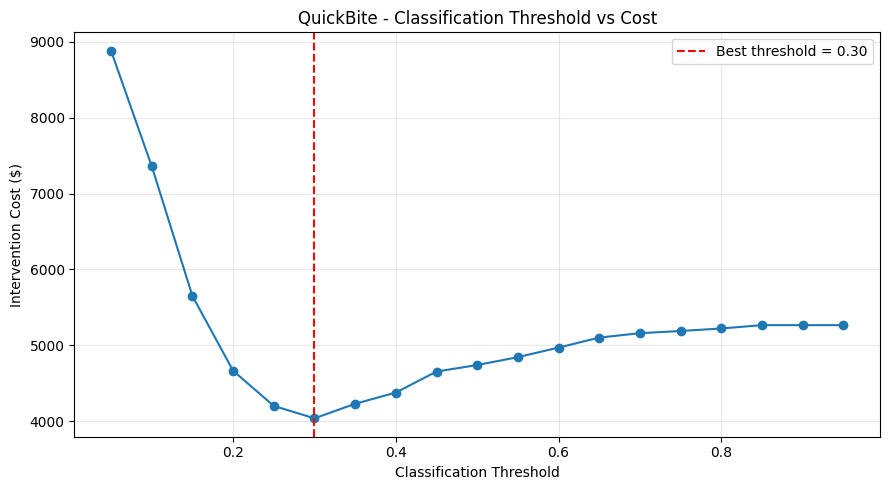

Best threshold: 0.3
Minimum training cost: $ 4036


In [ ]:

# Plot classification threshold versus intervention cost

# Reproduce the training cross-validation setup
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42,
)

# Generate out-of-fold predictions using training data only
oof_probabilities = cross_val_predict(
    model,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1,
)[:, 1]

# Test classification thresholds from 0.05 to 0.95
thresholds = np.arange(1, 20) / 20

costs = []

for threshold in thresholds:
    predictions = (oof_probabilities >= threshold).astype(int)
    cost = calculate_cost(y_train, predictions)
    costs.append(cost)

# Find the threshold with the lowest cost
best_index = np.argmin(costs)
best_threshold = thresholds[best_index]

# Plot results
plt.figure(figsize=(9, 5))
plt.plot(thresholds, costs, marker="o")

plt.axvline(
    best_threshold,
    color="red",
    linestyle="--",
    label=f"Best threshold = {best_threshold:.2f}",
)

plt.title("QuickBite - Classification Threshold vs Cost")
plt.xlabel("Classification Threshold")
plt.ylabel("Intervention Cost ($)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

print("Best threshold:", round(best_threshold, 2))
print("Minimum training cost: $", min(costs))


### QuickBite — Final Business Recommendation

The Logistic Regression model is recommended for predicting late food deliveries. With a test accuracy of 85.2%, ROC-AUC of 0.796, and recall of 45.3%.

Using the cost-optimized classification threshold of 0.30, the model generated an intervention cost of $1,360 across 750 test orders. This represents a saving of $395 (22.5%) compared with flagging nobody ($1,755). Flagging every order would cost $3,000.

The confusion matrix shows that the model correctly identified 53 late orders but missed 64. This indicates that additional improvements in recall could further reduce costs.

Hyperparameter tuning produced only a small ROC-AUC improvement that did not exceed cross-validation variability.

**Recommendation:** Pilot the model using the 0.30 threshold, monitor missed late orders and voucher expenses, and periodically review model performance before expanding deployment.